In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch version:", torch.__version__)

Device: cuda
PyTorch version: 2.14.1+cu130


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

for root, dirs, files_list in os.walk('/content/drive/MyDrive'):
    for file in files_list:
        if file == 'RML2016.10a_dict.pkl':
            pkl_file = os.path.join(root, file)
            print("Dataset found:", pkl_file)

Dataset found: /content/drive/MyDrive/RML2016.10a_dict.pkl


In [4]:
import pickle

with open(pkl_file, 'rb') as f:
    data = pickle.load(f, encoding='latin1')

print("Dataset loaded successfully!")
print("Total modulation-SNR combinations:", len(data))


Dataset loaded successfully!
Total modulation-SNR combinations: 220


In [5]:
print("First 5 keys:", list(data.keys())[:5])

key = list(data.keys())[0]

print("Sample key:", key)
print("Sample shape:", data[key].shape)

First 5 keys: [('QPSK', 2), ('PAM4', 8), ('AM-DSB', -4), ('GFSK', 6), ('QAM64', 8)]
Sample key: ('QPSK', 2)
Sample shape: (1000, 2, 128)


In [6]:
import numpy as np

modulations = sorted(set(k[0] for k in data.keys()))
snrs = sorted(set(k[1] for k in data.keys()))

print("Modulation classes:", modulations)
print("Number of classes:", len(modulations))
print("SNR values:", snrs)
print("Number of SNR levels:", len(snrs))

X = []
Y = []
SNR = []

for modulation in modulations:
    for snr in snrs:

        samples = data[(modulation, snr)]

        for sample in samples:

            sample = sample.astype(np.float32)

            # Normalize I-Q signal
            sample = sample / (np.sqrt(np.mean(sample**2)) + 1e-8)

            # Convert (2,128) to (128,2)
            X.append(sample.T)

            Y.append(modulations.index(modulation))
            SNR.append(snr)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.int64)
SNR = np.array(SNR)

print("\nPreprocessing completed!")
print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("SNR shape:", SNR.shape)

Modulation classes: ['8PSK', 'AM-DSB', 'AM-SSB', 'BPSK', 'CPFSK', 'GFSK', 'PAM4', 'QAM16', 'QAM64', 'QPSK', 'WBFM']
Number of classes: 11
SNR values: [-20, -18, -16, -14, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18]
Number of SNR levels: 20

Preprocessing completed!
X shape: (220000, 128, 2)
Y shape: (220000,)
SNR shape: (220000,)


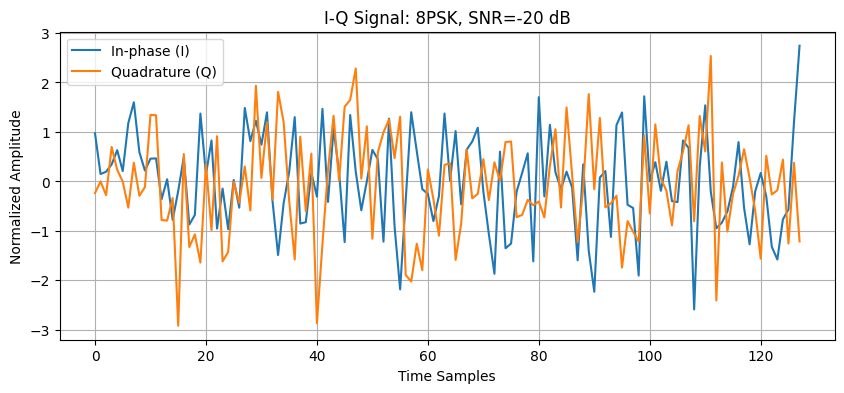

In [7]:
idx = 100

plt.figure(figsize=(10,4))

plt.plot(X[idx,:,0], label='In-phase (I)')
plt.plot(X[idx,:,1], label='Quadrature (Q)')

plt.title(
    f'I-Q Signal: {modulations[Y[idx]]}, SNR={SNR[idx]} dB'
)

plt.xlabel('Time Samples')
plt.ylabel('Normalized Amplitude')
plt.legend()
plt.grid()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

# Stratify using modulation and SNR combinations
strata = np.array([
    modulations.index(m) * len(snrs) + snrs.index(s)
    for m, s in zip(
        [modulations[i] for i in Y],
        SNR
    )
])

X_train, X_test, y_train, y_test, snr_train, snr_test = train_test_split(
    X, Y, SNR,
    test_size=0.2,
    random_state=42,
    stratify=strata
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (176000, 128, 2)
Testing data: (44000, 128, 2)
Training labels: (176000,)
Testing labels: (44000,)


In [9]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


class AMCDataset(Dataset):

    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# Use a smaller training subset for faster execution
np.random.seed(42)

indices = np.random.choice(
    len(X_train),
    min(30000, len(X_train)),
    replace=False
)

X_train_small = X_train[indices]
y_train_small = y_train[indices]

train_dataset = AMCDataset(X_train_small, y_train_small)
test_dataset = AMCDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=512,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))
print("DataLoaders created successfully!")

Using device: cuda
Training batches: 235
Testing batches: 86
DataLoaders created successfully!


In [10]:
class SequenceTransformer(nn.Module):

    def __init__(self, num_classes):
        super(SequenceTransformer, self).__init__()

        # Input projection: 2 features to 128 dimensions
        self.embedding = nn.Linear(2, 128)

        # Learnable CLS token
        self.cls_token = nn.Parameter(torch.randn(1, 1, 128))

        # Positional embedding
        self.pos_embedding = nn.Parameter(
            torch.randn(1, 129, 128) * 0.02
        )

        # Transformer encoder layer
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=128,
            nhead=8,
            dim_feedforward=256,
            dropout=0.1,
            batch_first=True
        )

        # Four encoder layers
        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=4
        )

        # Classification head
        self.norm = nn.LayerNorm(128)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):

        x = self.embedding(x)

        # Add CLS token
        cls = self.cls_token.expand(x.size(0), -1, -1)

        x = torch.cat((cls, x), dim=1)

        # Add positional information
        x = x + self.pos_embedding

        # Transformer encoder
        x = self.transformer(x)

        # Extract CLS token output
        x = x[:, 0, :]

        x = self.norm(x)

        return self.fc(x)


# Initialize model
sequence_model = SequenceTransformer(
    num_classes=len(modulations)
).to(device)

print(sequence_model)

print("\nSequence Transformer created successfully!")
print("Number of classes:", len(modulations))

SequenceTransformer(
  (embedding): Linear(in_features=2, out_features=128, bias=True)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (fc): Linear(in_features=128, out_features=11, bias=True)
)

Sequence Transformer created successfully!
N

In [11]:
criterion = nn.CrossEntropyLoss()

sequence_optimizer = torch.optim.Adam(
    sequence_model.parameters(),
    lr=2e-4
)

epochs = 3

sequence_history = []

for epoch in range(epochs):

    sequence_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        sequence_optimizer.zero_grad()

        outputs = sequence_model(xb)

        loss = criterion(outputs, yb)

        loss.backward()

        sequence_optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == yb).sum().item()
        total += yb.size(0)

    accuracy = 100 * correct / total
    avg_loss = total_loss / len(train_loader)

    sequence_history.append(avg_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.4f} "
        f"Accuracy: {accuracy:.2f}%"
    )

print("\nSequence Transformer training completed!")

Epoch [1/3] Loss: 2.0264 Accuracy: 24.48%
Epoch [2/3] Loss: 1.6704 Accuracy: 37.69%
Epoch [3/3] Loss: 1.5714 Accuracy: 40.86%

Sequence Transformer training completed!


In [12]:
from sklearn.metrics import accuracy_score

def evaluate_snr(model, X_test, y_test, snr_test):

    model.eval()
    results = {}

    with torch.no_grad():

        for snr in sorted(np.unique(snr_test)):

            indices = np.where(snr_test == snr)[0]

            predictions = []

            for start in range(0, len(indices), 512):

                batch_indices = indices[start:start+512]

                xb = torch.tensor(
                    X_test[batch_indices],
                    dtype=torch.float32
                ).to(device)

                outputs = model(xb)

                predictions.extend(
                    outputs.argmax(dim=1).cpu().numpy()
                )

            accuracy = accuracy_score(
                y_test[indices],
                predictions
            )

            results[snr] = accuracy * 100

    return results


seq_results = evaluate_snr(
    sequence_model,
    X_test,
    y_test,
    snr_test
)

print("Sequence Transformer SNR-wise Accuracy:\n")

for snr, acc in seq_results.items():
    print(f"SNR: {snr:>3} dB | Accuracy: {acc:.2f}%")

Sequence Transformer SNR-wise Accuracy:

SNR: -20 dB | Accuracy: 9.27%
SNR: -18 dB | Accuracy: 9.64%
SNR: -16 dB | Accuracy: 9.41%
SNR: -14 dB | Accuracy: 9.95%
SNR: -12 dB | Accuracy: 10.77%
SNR: -10 dB | Accuracy: 14.36%
SNR:  -8 dB | Accuracy: 22.55%
SNR:  -6 dB | Accuracy: 29.09%
SNR:  -4 dB | Accuracy: 34.14%
SNR:  -2 dB | Accuracy: 36.55%
SNR:   0 dB | Accuracy: 48.09%
SNR:   2 dB | Accuracy: 59.36%
SNR:   4 dB | Accuracy: 63.64%
SNR:   6 dB | Accuracy: 64.82%
SNR:   8 dB | Accuracy: 63.27%
SNR:  10 dB | Accuracy: 64.82%
SNR:  12 dB | Accuracy: 63.36%
SNR:  14 dB | Accuracy: 65.77%
SNR:  16 dB | Accuracy: 63.41%
SNR:  18 dB | Accuracy: 64.68%


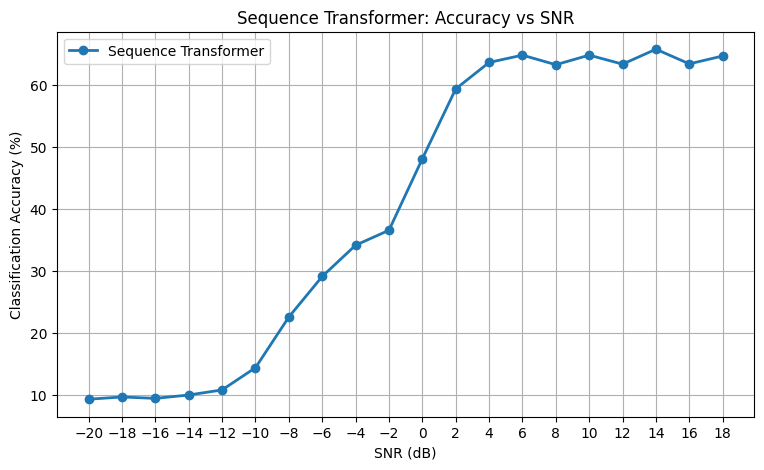

In [13]:
plt.figure(figsize=(9,5))

plt.plot(
    list(seq_results.keys()),
    list(seq_results.values()),
    marker='o',
    linewidth=2,
    label='Sequence Transformer'
)

plt.xlabel('SNR (dB)')
plt.ylabel('Classification Accuracy (%)')
plt.title('Sequence Transformer: Accuracy vs SNR')

plt.xticks(sorted(seq_results.keys()))
plt.grid(True)
plt.legend()

plt.savefig(
    'Sequence_Transformer_Accuracy.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [14]:
class VisionTransformer(nn.Module):

    def __init__(self, num_classes):
        super(VisionTransformer, self).__init__()

        # Convert each 4x4 patch into 128-dimensional embedding
        self.patch_embedding = nn.Conv2d(
            in_channels=1,
            out_channels=128,
            kernel_size=4,
            stride=4
        )

        # 16 patches (16x16 image with 4x4 patches)
        self.pos_embedding = nn.Parameter(
            torch.randn(1, 16, 128) * 0.02
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=128,
            nhead=8,
            dim_feedforward=256,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=4
        )

        # Classification head
        self.norm = nn.LayerNorm(128)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):

        # Convert (128,2) into original (2,128) I-Q arrangement
        x = x.transpose(1, 2)

        # Reshape into 16x16 single-channel image
        x = x.reshape(x.size(0), 1, 16, 16)

        # Extract patches
        x = self.patch_embedding(x)

        # Convert patches into sequence
        x = x.flatten(2).transpose(1, 2)

        # Add positional embeddings
        x = x + self.pos_embedding

        # Transformer encoder
        x = self.transformer(x)

        # Average pooling
        x = x.mean(dim=1)

        x = self.norm(x)

        return self.fc(x)


# Initialize Vision Transformer
vit_model = VisionTransformer(
    num_classes=len(modulations)
).to(device)

print(vit_model)
print("\nVision Transformer created successfully!")

VisionTransformer(
  (patch_embedding): Conv2d(1, 128, kernel_size=(4, 4), stride=(4, 4))
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (fc): Linear(in_features=128, out_features=11, bias=True)
)

Vision Transformer created successfully!


In [15]:
vit_optimizer = torch.optim.Adam(
    vit_model.parameters(),
    lr=2e-4
)

vit_epochs = 3

vit_history = []

for epoch in range(vit_epochs):

    vit_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        vit_optimizer.zero_grad()

        outputs = vit_model(xb)

        loss = criterion(outputs, yb)

        loss.backward()

        vit_optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == yb).sum().item()
        total += yb.size(0)

    accuracy = 100 * correct / total
    avg_loss = total_loss / len(train_loader)

    vit_history.append(avg_loss)

    print(
        f"Epoch [{epoch+1}/{vit_epochs}] "
        f"Loss: {avg_loss:.4f} "
        f"Accuracy: {accuracy:.2f}%"
    )

print("\nVision Transformer training completed!")

Epoch [1/3] Loss: 1.9716 Accuracy: 26.79%
Epoch [2/3] Loss: 1.7911 Accuracy: 31.93%
Epoch [3/3] Loss: 1.7324 Accuracy: 33.70%

Vision Transformer training completed!


In [16]:
vit_results = evaluate_snr(
    vit_model,
    X_test,
    y_test,
    snr_test
)

print("Vision Transformer SNR-wise Accuracy:\n")

for snr, acc in vit_results.items():
    print(f"SNR: {snr:>3} dB | Accuracy: {acc:.2f}%")

Vision Transformer SNR-wise Accuracy:

SNR: -20 dB | Accuracy: 8.68%
SNR: -18 dB | Accuracy: 9.73%
SNR: -16 dB | Accuracy: 9.36%
SNR: -14 dB | Accuracy: 11.55%
SNR: -12 dB | Accuracy: 12.59%
SNR: -10 dB | Accuracy: 16.05%
SNR:  -8 dB | Accuracy: 25.59%
SNR:  -6 dB | Accuracy: 32.14%
SNR:  -4 dB | Accuracy: 42.18%
SNR:  -2 dB | Accuracy: 45.23%
SNR:   0 dB | Accuracy: 46.86%
SNR:   2 dB | Accuracy: 48.55%
SNR:   4 dB | Accuracy: 49.36%
SNR:   6 dB | Accuracy: 49.95%
SNR:   8 dB | Accuracy: 46.41%
SNR:  10 dB | Accuracy: 48.82%
SNR:  12 dB | Accuracy: 49.77%
SNR:  14 dB | Accuracy: 47.95%
SNR:  16 dB | Accuracy: 49.36%
SNR:  18 dB | Accuracy: 47.68%


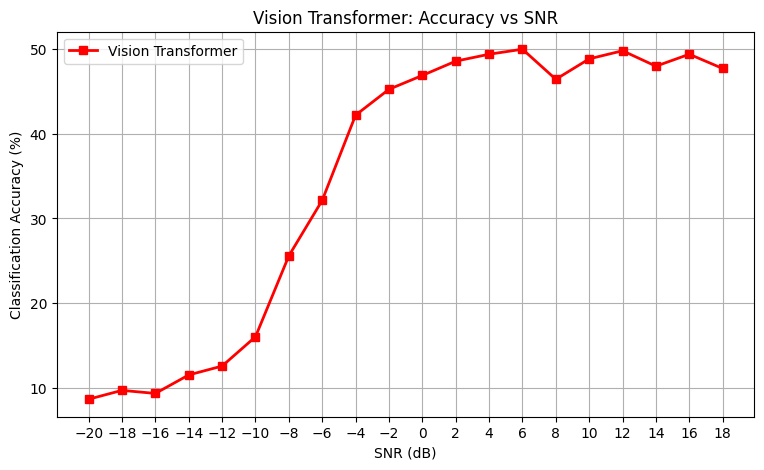

In [17]:
plt.figure(figsize=(9,5))

plt.plot(
    list(vit_results.keys()),
    list(vit_results.values()),
    marker='s',
    linewidth=2,
    color='red',
    label='Vision Transformer'
)

plt.xlabel('SNR (dB)')
plt.ylabel('Classification Accuracy (%)')
plt.title('Vision Transformer: Accuracy vs SNR')

plt.xticks(sorted(vit_results.keys()))
plt.grid(True)
plt.legend()

plt.savefig(
    'Vision_Transformer_Accuracy.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [18]:
vit_results = evaluate_snr(
    vit_model, X_test, y_test, snr_test
)

print("VISION TRANSFORMER RESULTS")
for snr, acc in vit_results.items():
    print(f"SNR: {snr:>3} dB | Accuracy: {acc:.2f}%")

print("\nSEQUENCE TRANSFORMER RESULTS")
for snr, acc in seq_results.items():
    print(f"SNR: {snr:>3} dB | Accuracy: {acc:.2f}%")

VISION TRANSFORMER RESULTS
SNR: -20 dB | Accuracy: 8.68%
SNR: -18 dB | Accuracy: 9.73%
SNR: -16 dB | Accuracy: 9.36%
SNR: -14 dB | Accuracy: 11.55%
SNR: -12 dB | Accuracy: 12.59%
SNR: -10 dB | Accuracy: 16.05%
SNR:  -8 dB | Accuracy: 25.59%
SNR:  -6 dB | Accuracy: 32.14%
SNR:  -4 dB | Accuracy: 42.18%
SNR:  -2 dB | Accuracy: 45.23%
SNR:   0 dB | Accuracy: 46.86%
SNR:   2 dB | Accuracy: 48.55%
SNR:   4 dB | Accuracy: 49.36%
SNR:   6 dB | Accuracy: 49.95%
SNR:   8 dB | Accuracy: 46.41%
SNR:  10 dB | Accuracy: 48.82%
SNR:  12 dB | Accuracy: 49.77%
SNR:  14 dB | Accuracy: 47.95%
SNR:  16 dB | Accuracy: 49.36%
SNR:  18 dB | Accuracy: 47.68%

SEQUENCE TRANSFORMER RESULTS
SNR: -20 dB | Accuracy: 9.27%
SNR: -18 dB | Accuracy: 9.64%
SNR: -16 dB | Accuracy: 9.41%
SNR: -14 dB | Accuracy: 9.95%
SNR: -12 dB | Accuracy: 10.77%
SNR: -10 dB | Accuracy: 14.36%
SNR:  -8 dB | Accuracy: 22.55%
SNR:  -6 dB | Accuracy: 29.09%
SNR:  -4 dB | Accuracy: 34.14%
SNR:  -2 dB | Accuracy: 36.55%
SNR:   0 dB | Accura

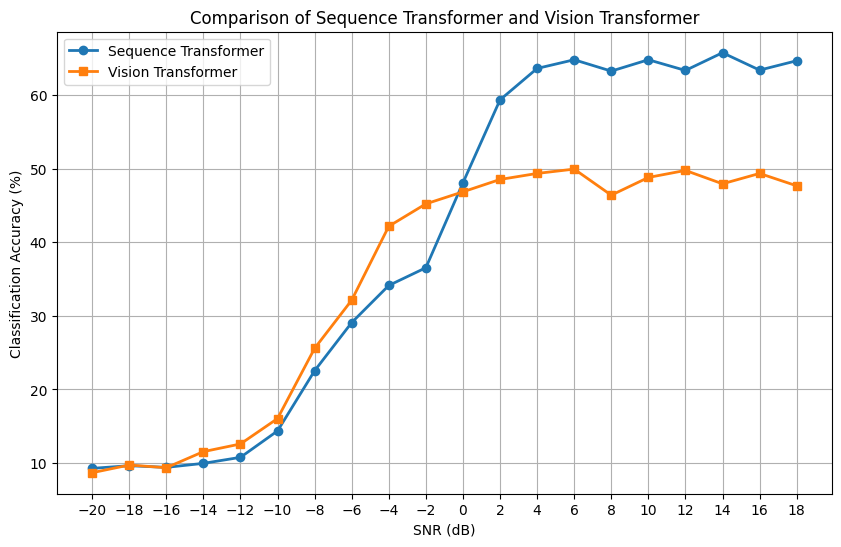

In [19]:
plt.figure(figsize=(10,6))

plt.plot(
    list(seq_results.keys()),
    list(seq_results.values()),
    marker='o',
    linewidth=2,
    label='Sequence Transformer'
)

plt.plot(
    list(vit_results.keys()),
    list(vit_results.values()),
    marker='s',
    linewidth=2,
    label='Vision Transformer'
)

plt.xlabel('SNR (dB)')
plt.ylabel('Classification Accuracy (%)')
plt.title('Comparison of Sequence Transformer and Vision Transformer')

plt.xticks(sorted(seq_results.keys()))
plt.grid(True)
plt.legend()

plt.savefig(
    'Transformer_Comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [20]:
import pandas as pd

results_df = pd.DataFrame({
    'SNR (dB)': list(seq_results.keys()),
    'Sequence Transformer (%)': list(seq_results.values()),
    'Vision Transformer (%)': list(vit_results.values())
})

display(results_df)

results_df.to_csv('Lab6_Results.csv', index=False)

,SNR (dB),Sequence Transformer (%),Vision Transformer (%)
0,-20,9.272727,8.681818
1,-18,9.636364,9.727273
2,-16,9.409091,9.363636
3,-14,9.954545,11.545455
4,-12,10.772727,12.590909
5,-10,14.363636,16.045455
6,-8,22.545455,25.590909
7,-6,29.090909,32.136364
8,-4,34.136364,42.181818
9,-2,36.545455,45.227273


In [21]:
def overall_accuracy(model, loader):

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            outputs = model(xb)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == yb).sum().item()
            total += yb.size(0)

    return 100 * correct / total


print("Sequence Transformer Test Accuracy:",
      round(overall_accuracy(sequence_model, test_loader), 2), "%")

print("Vision Transformer Test Accuracy:",
      round(overall_accuracy(vit_model, test_loader), 2), "%")

Sequence Transformer Test Accuracy: 40.35 %
Vision Transformer Test Accuracy: 34.89 %


In [22]:
import zipfile
import os

result_files = [
    'Sequence_Transformer_Accuracy.png',
    'Vision_Transformer_Accuracy.png',
    'Transformer_Comparison.png',
    'Lab6_Results.csv'
]

with zipfile.ZipFile('Lab6_Results.zip', 'w') as z:

    for file in result_files:
        if os.path.exists(file):
            z.write(file)

print("All result files saved successfully!")

All result files saved successfully!


In [23]:
from google.colab import files
files.download('Lab6_Results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>